# Classificador de imagens com CNN, versão 2

Evolução da versão 1: uma rede mais profunda (três blocos convolucionais) com as técnicas abaixo
para reduzir o overfitting e melhorar a generalização.

- **Duas convoluções por bloco com BatchNormalization**, para estabilizar o treino;
- **Aumento de dados** (`RandomFlip`, `RandomTranslation`), ativo só no treino;
- **Dropout** nos blocos e na camada densa;
- **ReduceLROnPlateau**: reduz o learning rate quando a validação estagna;
- **EarlyStopping** com restauração dos melhores pesos.

Treinado na GPU; a acurácia de teste fica em torno de 84%, contra ~70% da versão 1.

In [1]:
# Habilita a GPU: pré-carrega as bibliotecas CUDA do pacote nvidia antes de importar o TensorFlow.
import ctypes, glob, importlib.util, os
_pkg = os.path.dirname(importlib.util.find_spec("nvidia").submodule_search_locations[0])
for _lib in sorted(glob.glob(os.path.join(_pkg, "nvidia", "*", "lib", "*.so*"))):
    try:
        ctypes.CDLL(_lib, mode=ctypes.RTLD_GLOBAL)
    except OSError:
        pass
import tensorflow as tf
print("GPUs disponíveis:", tf.config.list_physical_devices("GPU"))

I0000 00:00:1792895534.600957  292865 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


GPUs disponíveis: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import numpy as np
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train_full, y_test = y_train_full.ravel(), y_test.ravel()

CLASSES = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Validação separada do treino, para acompanhar o overfitting sem tocar no teste.
X_train, X_val = X_train_full[:45000], X_train_full[45000:]
y_train, y_val = y_train_full[:45000], y_train_full[45000:]
print(X_train.shape, X_val.shape, X_test.shape)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


## 1. Arquitetura

In [3]:
def conv_block(filters):
    return [
        tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Dropout(0.25),
    ]

layers = [
    tf.keras.Input(shape=(32, 32, 3)),
    # Aumento de dados: ativo só durante o treino.
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
]
for filters in (32, 64, 128):
    layers += conv_block(filters)
layers += [
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation="softmax"),
]
model = tf.keras.Sequential(layers, name="cnn_v2")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

I0000 00:00:1792895538.758707  292865 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4132 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "cnn_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,45

 Total params: 815,466 (3.11 MB)

 Trainable params: 814,570 (3.11 MB)

 Non-trainable params: 896 (3.50 KB)

## 2. Treino

O EarlyStopping interrompe o treino quando a perda de validação para de cair e restaura os melhores pesos.

In [4]:
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
]
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=128,
    callbacks=callbacks,
    verbose=0,
)
print(f"Épocas executadas: {len(history.history['loss'])}")

W0000 00:00:1792895539.720262  292865 cpu_allocator_impl.cc:82] Allocation of 552960000 exceeds 10% of free system memory.
W0000 00:00:1792895540.193231  292865 cpu_allocator_impl.cc:82] Allocation of 552960000 exceeds 10% of free system memory.


E0000 00:00:1792895542.245746  292865 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/cnn_v2_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


I0000 00:00:1792895543.422352  293060 cuda_dnn.cc:461] Loaded cuDNN version 92700


Épocas executadas: 40


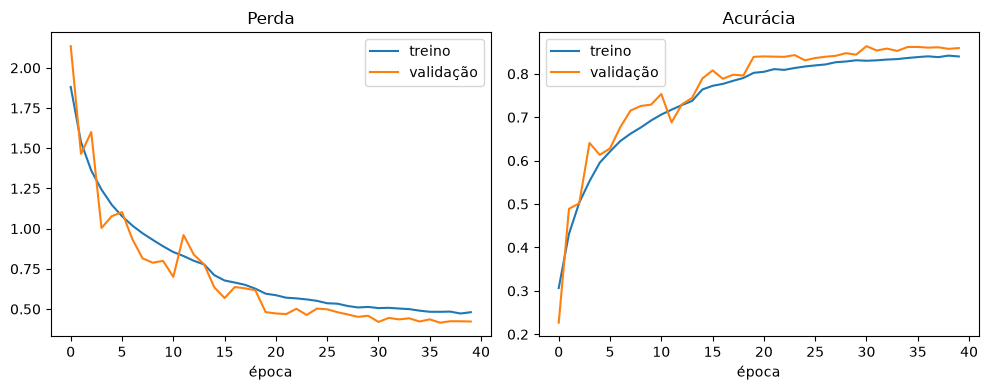

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history["loss"], label="treino")
axes[0].plot(history.history["val_loss"], label="validação")
axes[0].set_title("Perda")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="treino")
axes[1].plot(history.history["val_accuracy"], label="validação")
axes[1].set_title("Acurácia")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Avaliação no conjunto de teste

A camada de aumento de dados é desligada automaticamente na inferência.

In [6]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Teste: perda={test_loss:.4f}  acurácia={test_accuracy:.4f}")

Teste: perda=0.4529  acurácia=0.8490


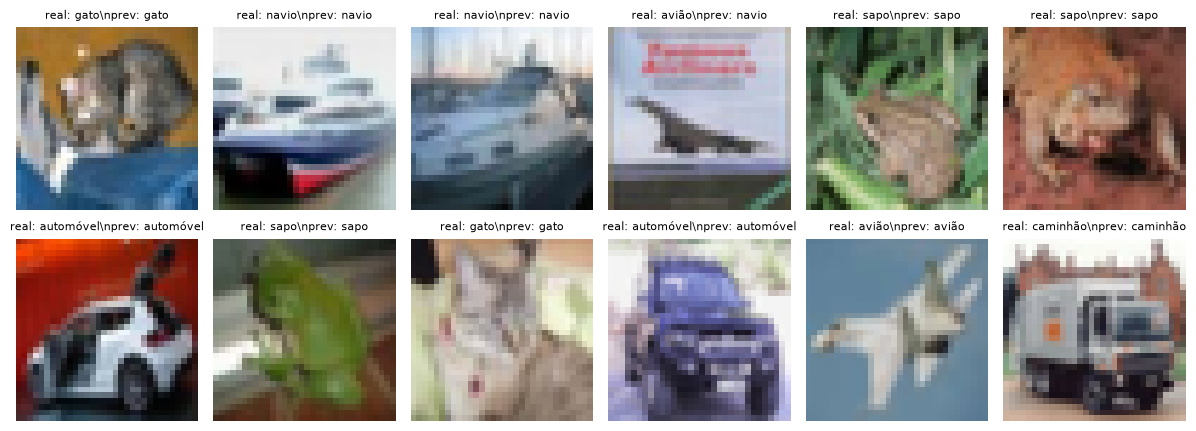

In [7]:
probs = model.predict(X_test[:12], verbose=0)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, prob, true in zip(axes.ravel(), X_test[:12], probs, y_test[:12]):
    ax.imshow(img)
    ax.set_title(f"real: {CLASSES[true]}\\nprev: {CLASSES[prob.argmax()]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()